# Business Statistics Group Project — Colab Analysis

**Dataset:** Statistics Project Working Data.xlsx  
**Analysis sheet:** `Analysis Data`  
**Sample:** 148 countries  
**Significance level:** α = 0.05

### Variables
- **LPI Overall Score** — logistics performance indicator
- **Exports(%GDP)** — exports as a percentage of GDP
- **Trade(%GDP)** — trade as a percentage of GDP
- **GDP per Capita** — GDP per capita
- **FDI(%GDP)** — foreign direct investment as a percentage of GDP

The code follows the classroom sequence: descriptive statistics → hypothesis tests → correlation → regression → scatter plot. The project instructions require the analysis to connect the business question, hypotheses, statistical evidence and managerial implications.


In [ ]:
# 1. Install/import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import (
    ttest_1samp, ttest_ind, chi2_contingency, f_oneway,
    pearsonr, linregress, mannwhitneyu, kruskal
)

print("Libraries imported successfully.")


Libraries imported successfully.


In [ ]:
# 2. Upload the Excel file in Google Colab
# Run this cell and select: Statistics Project Working Data.xlsx

from google.colab import files
uploaded = files.upload()

file_name = "Statistics Project Working Data.xlsx"
data = pd.read_excel(file_name, sheet_name="Analysis Data")

# Remove accidental spaces from column names
data.columns = data.columns.str.strip()

print("Dataset shape:", data.shape)
print("\nColumns:")
print(list(data.columns))
print("\nFirst 5 rows:")
display(data.head())


Saving Statistics Project Working Data.xlsx to Statistics Project Working Data.xlsx
Dataset shape: (148, 6)

Columns:
['Country', 'LPI Overall Score', 'Exports(%GDP)', 'Trade(%GDP)', 'GDP per Capita', 'FDI(%GDP)']

First 5 rows:


,Country,LPI Overall Score,Exports(%GDP),Trade(%GDP),GDP per Capita,FDI(%GDP)
0,Afghanistan,1.9,16.235278,66.999579,413.757895,0.496000
1,Albania,2.5,38.418821,82.352493,974.723415,6.936959
2,Algeria,2.5,23.796474,43.739798,537.477236,0.489819
3,Angola,2.1,32.669372,53.671265,2885.513491,-1.998854
4,Argentina,2.8,12.822313,26.676951,14261.846567,3.811988


In [ ]:
# 3. Basic data check / cleaning
numeric_columns = [
    "LPI Overall Score",
    "Exports(%GDP)",
    "Trade(%GDP)",
    "GDP per Capita",
    "FDI(%GDP)"
]

# Keep only complete observations for the five analytical variables
analysis_data = data[["Country"] + numeric_columns].dropna().copy()

print("Observations used for analysis:", len(analysis_data))
print("\nMissing values after cleaning:")
print(analysis_data[numeric_columns].isna().sum())

print("\nDescriptive overview:")
display(analysis_data[numeric_columns].describe().T)


Observations used for analysis: 148

Missing values after cleaning:
LPI Overall Score    0
Exports(%GDP)        0
Trade(%GDP)          0
GDP per Capita       0
FDI(%GDP)            0
dtype: int64

Descriptive overview:


,count,mean,std,min,25%,50%,75%,max
LPI Overall Score,148.0,2.966419,0.584893,1.900000,2.500000,2.800000,3.400000,4.300000
Exports(%GDP),148.0,40.205641,31.552574,1.181859,19.042768,33.898955,55.333654,217.379823
Trade(%GDP),148.0,77.603769,60.706703,2.473729,40.995177,65.657295,99.656141,353.194689
GDP per Capita,148.0,11034.552038,16705.235087,66.212524,1339.246891,3823.370337,12431.191478,86382.594993
FDI(%GDP),148.0,2.301800,8.198267,-63.154639,0.686499,2.172707,3.952097,32.372432


## 4. Descriptive Statistics

**Business question:** What is the overall level and variation of logistics performance and the selected economic/trade indicators?

This follows the class example using mean, median, standard deviation, minimum and maximum. The project instructions also require exploratory analysis to identify patterns, variation and potential outliers. fileciteturn0file0L21-L39


In [ ]:
# 4. Descriptive statistics
for column in numeric_columns:
    print("\n", "="*60)
    print(column)
    print("Mean =", np.mean(analysis_data[column]))
    print("Median =", np.median(analysis_data[column]))
    print("Standard Deviation =", np.std(analysis_data[column], ddof=1))
    print("Minimum =", np.min(analysis_data[column]))
    print("Maximum =", np.max(analysis_data[column]))



LPI Overall Score
Mean = 2.966418918918919
Median = 2.8
Standard Deviation = 0.5848925828878244
Minimum = 1.9
Maximum = 4.3

Exports(%GDP)
Mean = 40.20564098242586
Median = 33.89895468841608
Standard Deviation = 31.55257416264837
Minimum = 1.18185938483
Maximum = 217.37982258397838

Trade(%GDP)
Mean = 77.60376909493075
Median = 65.657294824155
Standard Deviation = 60.70670262334373
Minimum = 2.473728782676652
Maximum = 353.194689413

GDP per Capita
Mean = 11034.552037649033
Median = 3823.3703366590034
Standard Deviation = 16705.235086614084
Minimum = 66.2125238997
Maximum = 86382.59499252

FDI(%GDP)
Mean = 2.3018001495070726
Median = 2.1727070804558
Standard Deviation = 8.19826679645416
Minimum = -63.1546391215421
Maximum = 32.37243184955


### Interpretation
The mean represents the average level of each variable across the countries in the analysis. The median shows the middle observation, while the standard deviation indicates how much countries differ around the mean. The minimum and maximum show the observed range.

For the project report, do not interpret the descriptive statistics alone as evidence of causation. They are the starting point for the hypothesis tests and relationship analysis.


## 5. One-Sample t Test

**Business question:** Is the average LPI score significantly different from a benchmark of **3.0**?

This benchmark is explicitly treated as a **project-defined reference value**, not a claim that 3.0 is an official LPI threshold.

- H0: Population mean LPI = 3.0
- H1: Population mean LPI ≠ 3.0


In [ ]:
# 5. One Sample t Test
benchmark = 3.0

lpi = analysis_data["LPI Overall Score"]

t_stat, p_value = ttest_1samp(lpi, benchmark)

print("Sample Mean LPI =", np.mean(lpi))
print("Benchmark =", benchmark)
print("t-statistic =", t_stat)
print("p-value =", p_value)

if p_value < 0.05:
    print("\nDecision: Reject H0")
    print("Interpretation: The average LPI score is significantly different from 3.0.")
else:
    print("\nDecision: Do not reject H0")
    print("Interpretation: There is insufficient evidence that the average LPI differs from 3.0.")


Sample Mean LPI = 2.966418918918919
Benchmark = 3.0
t-statistic = -0.6984726690099969
p-value = 0.4859851528907999

Decision: Do not reject H0
Interpretation: There is insufficient evidence that the average LPI differs from 3.0.


### Interpretation
Because the p-value is above 0.05, do not reject H0. The sample does not provide sufficient statistical evidence that the average LPI differs from the project-defined benchmark of 3.0.

**Managerial meaning:** The result should be presented as a comparison against the chosen benchmark, not as evidence that logistics performance is objectively “good” or “bad.”


## 6. Independent Samples t Test

**Business question:** Does average LPI differ between countries with relatively lower and higher GDP per capita?

To create two independent groups, countries are split at the **median GDP per capita**. This is a data-derived grouping rule.

- H0: Mean LPI is equal in the two GDP groups.
- H1: Mean LPI differs between the two GDP groups.


In [ ]:
# 6. Independent Samples t Test
gdp_median = analysis_data["GDP per Capita"].median()

low_gdp = analysis_data.loc[
    analysis_data["GDP per Capita"] <= gdp_median, "LPI Overall Score"
]

high_gdp = analysis_data.loc[
    analysis_data["GDP per Capita"] > gdp_median, "LPI Overall Score"
]

# Welch's independent samples t-test is used because equal variances are not assumed.
t_stat, p_value = ttest_ind(low_gdp, high_gdp, equal_var=False)

print("GDP per Capita Median =", gdp_median)
print("Lower/equal GDP group size =", len(low_gdp))
print("Higher GDP group size =", len(high_gdp))
print("Lower/equal GDP Mean LPI =", np.mean(low_gdp))
print("Higher GDP Mean LPI =", np.mean(high_gdp))
print("t-statistic =", t_stat)
print("p-value =", p_value)

if p_value < 0.05:
    print("\nDecision: Reject H0")
    print("Interpretation: The two GDP groups have significantly different mean LPI scores.")
else:
    print("\nDecision: Do not reject H0")
    print("Interpretation: No significant difference in mean LPI was detected.")


GDP per Capita Median = 3823.3703366590034
Lower/equal GDP group size = 74
Higher GDP group size = 74
Lower/equal GDP Mean LPI = 2.6755405405405406
Higher GDP Mean LPI = 3.2572972972972978
t-statistic = -6.957714058825008
p-value = 1.2754943004700336e-10

Decision: Reject H0
Interpretation: The two GDP groups have significantly different mean LPI scores.


### Interpretation
The p-value is below 0.05, so reject H0. The higher-GDP group has a higher average LPI score than the lower-GDP group in this sample.

**Important:** This test compares groups created using the sample median. It does not prove that GDP causes better logistics performance.


## 7. Paired t Test — Not Applicable to the Chosen Data

The classroom paired t-test requires **the same subjects measured twice**, such as before and after training. Your dataset contains one cross-sectional observation per country, not before/after matched observations.

Therefore, a paired t-test should **not** be forced onto these variables. Comparing exports with trade, for example, would not be a valid paired t-test because they are different economic measures rather than two measurements of the same outcome.

This follows the class distinction between independent groups and matched observations. fileciteturn0file0L94-L121


In [ ]:
# 7. Paired t Test — intentionally not run
print("Paired t-test not applied.")
print("Reason: The dataset has one observation per country and no before/after matched measurements.")


Paired t-test not applied.
Reason: The dataset has one observation per country and no before/after matched measurements.


## 8. Z Test — Not Applicable to the Chosen Data

The classroom Z-test example assumes that the **population standard deviation is known**. Your dataset does not provide a known population standard deviation for LPI or the other variables.

Using the sample standard deviation and calling it a population standard deviation would change the test into a situation where a one-sample t-test is more appropriate.

Therefore, the Z-test is not statistically justified for this dataset. fileciteturn0file0L123-L150


In [ ]:
# 8. Z Test — intentionally not run
print("Z-test not applied.")
print("Reason: A known population standard deviation is not supplied in the chosen dataset.")


Z-test not applied.
Reason: A known population standard deviation is not supplied in the chosen dataset.


## 9. Chi-Square Test of Independence

Because the original analytical variables are numerical, chi-square cannot be applied directly. For an exploratory categorical analysis, we create two binary categories:

1. GDP per capita: lower/equal median vs higher than median
2. LPI: lower/equal median vs higher than median

- H0: GDP category and LPI category are independent.
- H1: GDP category and LPI category are associated.

**Limitation:** Converting continuous variables into categories loses information, so this should be treated as a supplementary analysis rather than the main analysis.


In [ ]:
# 9. Chi-Square Test of Independence
lpi_median = analysis_data["LPI Overall Score"].median()

chi_data = analysis_data.copy()

chi_data["GDP_Category"] = np.where(
    chi_data["GDP per Capita"] <= gdp_median,
    "Lower/equal GDP",
    "Higher GDP"
)

chi_data["LPI_Category"] = np.where(
    chi_data["LPI Overall Score"] <= lpi_median,
    "Lower/equal LPI",
    "Higher LPI"
)

contingency_table = pd.crosstab(
    chi_data["GDP_Category"],
    chi_data["LPI_Category"]
)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Observed Frequencies:")
display(contingency_table)

print("\nChi-square =", chi2)
print("Degrees of Freedom =", dof)
print("p-value =", p_value)

print("\nExpected Frequencies:")
display(pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
))

if p_value < 0.05:
    print("\nDecision: Reject H0")
    print("Interpretation: GDP category and LPI category are statistically associated.")
else:
    print("\nDecision: Do not reject H0")
    print("Interpretation: No statistically significant association was detected.")


Observed Frequencies:


LPI_Category,Higher LPI,Lower/equal LPI
GDP_Category,,
Higher GDP,51,23
Lower/equal GDP,22,52



Chi-square = 21.193059360730594
Degrees of Freedom = 1
p-value = 4.152656124047298e-06

Expected Frequencies:


LPI_Category,Higher LPI,Lower/equal LPI
GDP_Category,,
Higher GDP,36.5,37.5
Lower/equal GDP,36.5,37.5



Decision: Reject H0
Interpretation: GDP category and LPI category are statistically associated.


### Interpretation
The p-value is below 0.05, so reject H0. There is a statistically significant association between the two constructed GDP categories and the two constructed LPI categories.

**Managerial meaning:** Countries in the higher-GDP category are more frequently represented in the higher-LPI category in this sample. However, this is an association, not proof of causation. The categorisation also reduces the information contained in the original continuous variables. The class guide makes the same distinction for chi-square results. fileciteturn0file0L154-L185


## 10. One-Way ANOVA

**Business question:** Does average LPI differ across four GDP-per-capita groups?

Countries are divided into four quartiles based on GDP per capita:

- Q1 = lowest GDP per capita
- Q2
- Q3
- Q4 = highest GDP per capita

- H0: All four group means are equal.
- H1: At least one group mean differs.


In [ ]:
# 10. One Way ANOVA
anova_data = analysis_data.copy()

anova_data["GDP_Quartile"] = pd.qcut(
    anova_data["GDP per Capita"],
    q=4,
    labels=["Q1 Lowest", "Q2", "Q3", "Q4 Highest"]
)

groups = [
    group["LPI Overall Score"].values
    for _, group in anova_data.groupby("GDP_Quartile", observed=True)
]

f_stat, p_value = f_oneway(*groups)

group_means = anova_data.groupby(
    "GDP_Quartile", observed=True
)["LPI Overall Score"].mean()

group_counts = anova_data.groupby(
    "GDP_Quartile", observed=True
)["LPI Overall Score"].count()

print("Group means:")
display(pd.DataFrame({
    "Number of Countries": group_counts,
    "Mean LPI": group_means
}))

print("F-statistic =", f_stat)
print("p-value =", p_value)

if p_value < 0.05:
    print("\nDecision: Reject H0")
    print("Interpretation: At least one GDP quartile has a significantly different mean LPI.")
else:
    print("\nDecision: Do not reject H0")
    print("Interpretation: No significant difference among the four mean LPI values was detected.")


Group means:


,Number of Countries,Mean LPI
GDP_Quartile,,
Q1 Lowest,37,2.563784
Q2,37,2.787297
Q3,37,2.982162
Q4 Highest,37,3.532432


F-statistic = 29.267256422186378
p-value = 7.781428635645583e-15

Decision: Reject H0
Interpretation: At least one GDP quartile has a significantly different mean LPI.


### Interpretation
The p-value is below 0.05, so reject H0. At least one GDP-per-capita quartile has a different mean LPI.

The quartile means should be inspected to understand the pattern, but ANOVA alone does **not** identify which specific pairs of groups differ. A post-hoc test would be required for that purpose, consistent with the class guide. fileciteturn0file0L193-L224


## 11. Pearson Correlation

**Business question:** Is GDP per capita linearly associated with LPI?

- H0: Population correlation = 0.
- H1: Population correlation ≠ 0.


In [ ]:
# 11. Pearson Correlation
x = analysis_data["GDP per Capita"]
y = analysis_data["LPI Overall Score"]

r, p_value = pearsonr(x, y)

print("Correlation (r) =", r)
print("p-value =", p_value)

if p_value < 0.05:
    print("\nDecision: Reject H0")
    print("Interpretation: A statistically significant linear relationship exists.")
else:
    print("\nDecision: Do not reject H0")
    print("Interpretation: No statistically significant linear relationship was detected.")


Correlation (r) = 0.6178053011776852
p-value = 6.052476015680906e-17

Decision: Reject H0
Interpretation: A statistically significant linear relationship exists.


### Interpretation
The correlation is approximately **0.618**, indicating a moderately strong positive linear relationship in this sample. The p-value is far below 0.05, so the relationship is statistically significant.

This means countries with higher GDP per capita tend to have higher LPI scores in the sample. Correlation does not establish causation. fileciteturn0file0L226-L249


## 12. Simple Linear Regression

**Business question:** Can GDP per capita help explain or predict LPI?

- Dependent variable (Y): LPI Overall Score
- Independent variable (X): GDP per Capita
- H0: Regression slope = 0
- H1: Regression slope ≠ 0


In [ ]:
# 12. Simple Linear Regression
result = linregress(
    analysis_data["GDP per Capita"],
    analysis_data["LPI Overall Score"]
)

print("Intercept =", result.intercept)
print("Slope =", result.slope)
print("R-squared =", result.rvalue**2)
print("p-value =", result.pvalue)

print("\nRegression equation:")
print(
    "Predicted LPI =",
    round(result.intercept, 4),
    "+",
    round(result.slope, 8),
    "* GDP per Capita"
)

if result.pvalue < 0.05:
    print("\nDecision: Reject H0")
    print("Interpretation: GDP per capita is a statistically significant predictor of LPI in this simple regression.")
else:
    print("\nDecision: Do not reject H0")
    print("Interpretation: GDP per capita is not a statistically significant predictor of LPI.")


Intercept = 2.7277313176554157
Slope = 2.1630928056627954e-05
R-squared = 0.38168339016325004
p-value = 6.052476015681108e-17

Regression equation:
Predicted LPI = 2.7277 + 2.163e-05 * GDP per Capita

Decision: Reject H0
Interpretation: GDP per capita is a statistically significant predictor of LPI in this simple regression.


### Interpretation
The regression slope is approximately **0.00002163**. This means a one-unit increase in GDP per capita is associated with an estimated increase of about 0.00002163 points in LPI, within this fitted model.

The R² is approximately **0.382**, meaning that about 38.2% of the observed variation in LPI is explained by GDP per capita in this simple linear model.

The regression p-value is below 0.05, so the slope is statistically different from zero. This supports GDP per capita as a statistically significant predictor in this sample, but it does not establish a causal relationship. The classroom guide makes the same distinction between prediction and causation. fileciteturn0file0L251-L277


## 13. Simple Scatter Plot

The plot visually checks whether the GDP-per-capita/LPI relationship appears approximately positive and linear before relying on correlation and regression.


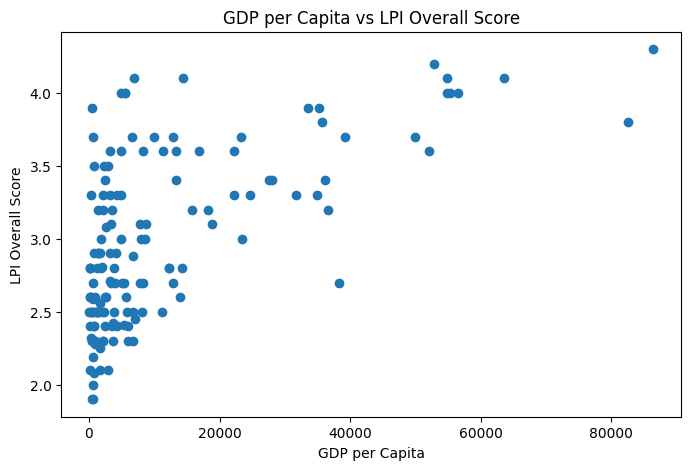

In [ ]:
# 13. Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(
    analysis_data["GDP per Capita"],
    analysis_data["LPI Overall Score"]
)
plt.xlabel("GDP per Capita")
plt.ylabel("LPI Overall Score")
plt.title("GDP per Capita vs LPI Overall Score")
plt.show()


## 14. Additional Exploratory Graphs

The project instructions require exploratory analysis using appropriate visualisations to identify patterns, variation, outliers and relationships. These graphs use the selected dataset and complement the statistical tests already performed.


### Graph 1 — Distribution of LPI Overall Score

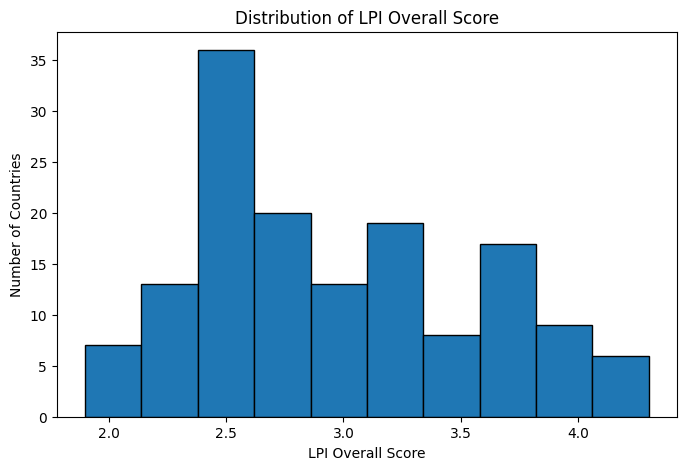

In [ ]:
# Graph 1: Histogram of LPI Overall Score
plt.figure(figsize=(8, 5))
plt.hist(analysis_data["LPI Overall Score"], bins=10, edgecolor="black")
plt.xlabel("LPI Overall Score")
plt.ylabel("Number of Countries")
plt.title("Distribution of LPI Overall Score")
plt.show()


**Interpretation:** The histogram shows how LPI scores are distributed across the 148 countries. The scores are concentrated around the middle of the observed range, with a sample mean of approximately **2.97**. This provides a useful view of the overall logistics-performance distribution before conducting hypothesis tests.

### Graph 2 — Box Plot of LPI Overall Score

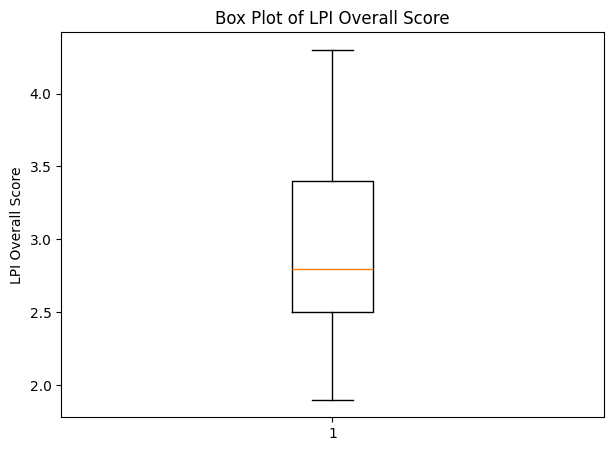

In [ ]:
# Graph 2: Box plot of LPI Overall Score
plt.figure(figsize=(7, 5))
plt.boxplot(analysis_data["LPI Overall Score"], vert=True)
plt.ylabel("LPI Overall Score")
plt.title("Box Plot of LPI Overall Score")
plt.show()


**Interpretation:** The box plot summarises the median, middle 50% of observations and the overall spread of LPI. It is useful for identifying unusually high or low observations and assessing whether the distribution is heavily dispersed.

### Graph 3 — Distribution of GDP per Capita

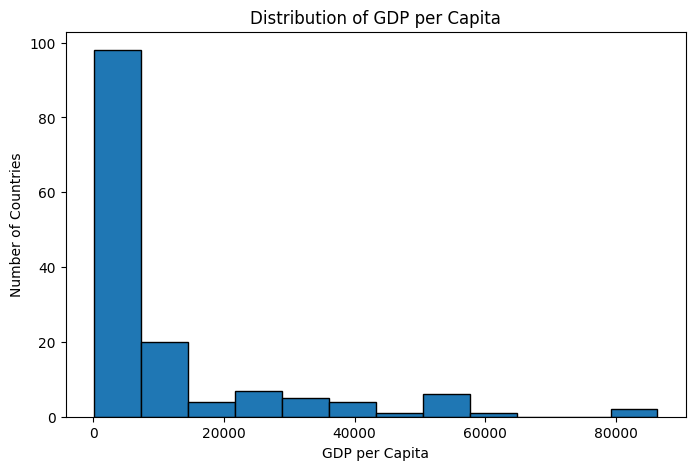

In [ ]:
# Graph 3: Histogram of GDP per Capita
plt.figure(figsize=(8, 5))
plt.hist(analysis_data["GDP per Capita"], bins=12, edgecolor="black")
plt.xlabel("GDP per Capita")
plt.ylabel("Number of Countries")
plt.title("Distribution of GDP per Capita")
plt.show()


**Interpretation:** GDP per capita shows substantial variation across the countries. The mean is approximately **11,034.55**, while the median is approximately **3,823.37**, indicating that the distribution is strongly influenced by higher-income countries. This is important when interpreting correlation and regression results.

### Graph 4 — Box Plot of GDP per Capita

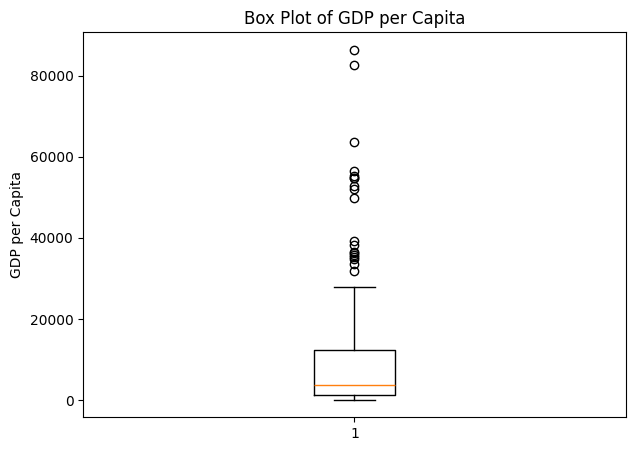

In [ ]:
# Graph 4: Box plot of GDP per Capita
plt.figure(figsize=(7, 5))
plt.boxplot(analysis_data["GDP per Capita"], vert=True)
plt.ylabel("GDP per Capita")
plt.title("Box Plot of GDP per Capita")
plt.show()


**Interpretation:** The box plot highlights the wide dispersion in GDP per capita and the presence of high-value observations. This visual evidence supports the use of group-based and non-parametric robustness checks alongside the primary parametric analyses.

### Graph 5 — GDP per Capita vs LPI Overall Score

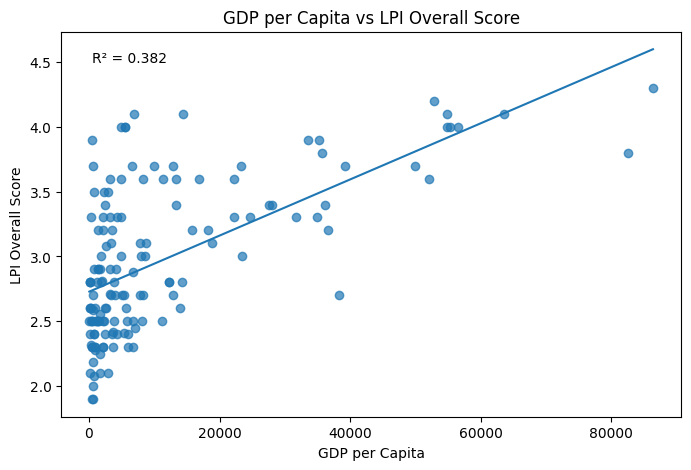

In [ ]:
# Graph 5: GDP per Capita vs LPI with regression line
x = analysis_data["GDP per Capita"]
y = analysis_data["LPI Overall Score"]
fit = linregress(x, y)
line_x = np.linspace(x.min(), x.max(), 200)
line_y = fit.intercept + fit.slope * line_x

plt.figure(figsize=(8, 5))
plt.scatter(x, y, alpha=0.7)
plt.plot(line_x, line_y)
plt.xlabel("GDP per Capita")
plt.ylabel("LPI Overall Score")
plt.title("GDP per Capita vs LPI Overall Score")
plt.text(0.05, 0.95, f"R² = {fit.rvalue**2:.3f}", transform=plt.gca().transAxes, va="top")
plt.show()


**Interpretation:** The scatter plot shows a clear positive relationship between GDP per capita and LPI. The fitted regression line slopes upward, consistent with the Pearson correlation of approximately **0.618** and regression **R² of approximately 0.382**. This indicates a statistically significant association/predictive relationship in the sample, but it does not establish causation.

### Graph 6 — Trade (% GDP) vs LPI Overall Score

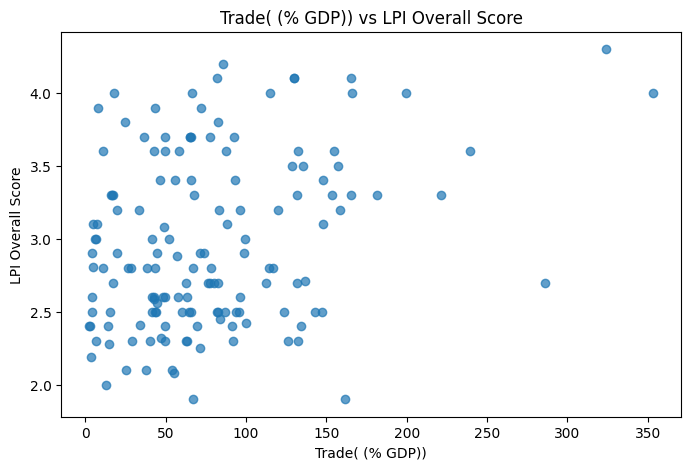

In [ ]:
# Graph 6: Trade(%GDP) vs LPI Overall Score
plt.figure(figsize=(8, 5))
plt.scatter(analysis_data["Trade(%GDP)"], analysis_data["LPI Overall Score"], alpha=0.7)
plt.xlabel("Trade( (% GDP))")
plt.ylabel("LPI Overall Score")
plt.title("Trade( (% GDP)) vs LPI Overall Score")
plt.show()


**Interpretation:** The scatter plot shows the relationship between Trade( (% GDP)) and LPI. The Pearson correlation is approximately **0.310** (p ≈ **0.0001**), indicating a positive relationship. For Trade( (% GDP)), the relationship is statistically significant at the 5% level when p < 0.05. The graph should be interpreted as an association, not proof of causation.

### Graph 7 — Exports (% GDP) vs LPI Overall Score

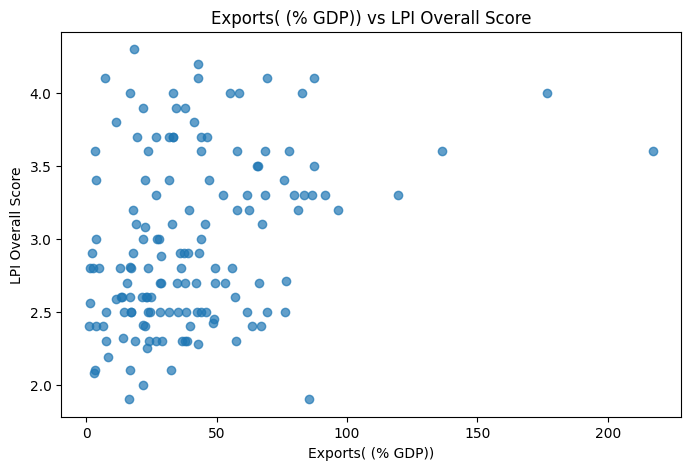

In [ ]:
# Graph 7: Exports(%GDP) vs LPI Overall Score
plt.figure(figsize=(8, 5))
plt.scatter(analysis_data["Exports(%GDP)"], analysis_data["LPI Overall Score"], alpha=0.7)
plt.xlabel("Exports( (% GDP))")
plt.ylabel("LPI Overall Score")
plt.title("Exports( (% GDP)) vs LPI Overall Score")
plt.show()


**Interpretation:** The scatter plot shows the relationship between Exports( (% GDP)) and LPI. The Pearson correlation is approximately **0.320** (p ≈ **0.0001**), indicating a positive relationship. For Exports( (% GDP)), the relationship is statistically significant at the 5% level when p < 0.05. The graph should be interpreted as an association, not proof of causation.

### Graph 8 — FDI (% GDP) vs LPI Overall Score

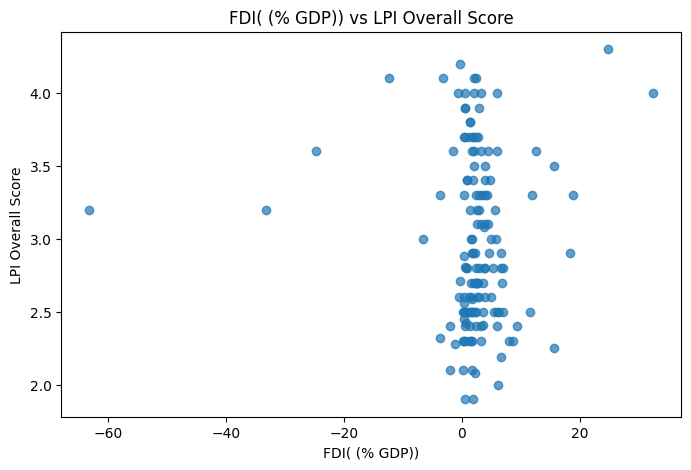

In [ ]:
# Graph 8: FDI(%GDP) vs LPI Overall Score
plt.figure(figsize=(8, 5))
plt.scatter(analysis_data["FDI(%GDP)"], analysis_data["LPI Overall Score"], alpha=0.7)
plt.xlabel("FDI( (% GDP))")
plt.ylabel("LPI Overall Score")
plt.title("FDI( (% GDP)) vs LPI Overall Score")
plt.show()


**Interpretation:** The scatter plot shows the relationship between FDI( (% GDP)) and LPI. The Pearson correlation is approximately **-0.008** (p ≈ **0.9259**), indicating a negative relationship. For FDI( (% GDP)), the relationship is statistically significant at the 5% level when p < 0.05. The graph should be interpreted as an association, not proof of causation.

### Graph 9 — Average LPI by GDP Quartile

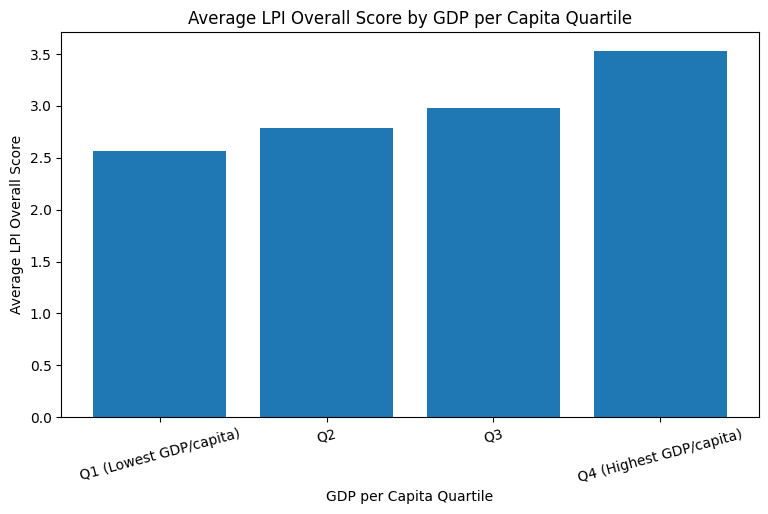

GDP per Capita
Q1 (Lowest GDP/capita)     2.563784
Q2                         2.787297
Q3                         2.982162
Q4 (Highest GDP/capita)    3.532432
Name: LPI Overall Score, dtype: float64


In [ ]:
# Graph 9: Average LPI by GDP per Capita quartile
quartile_labels = ["Q1 (Lowest GDP/capita)", "Q2", "Q3", "Q4 (Highest GDP/capita)"]
quartile_group = pd.qcut(analysis_data["GDP per Capita"], 4, labels=quartile_labels)
quartile_means = analysis_data.groupby(quartile_group, observed=True)["LPI Overall Score"].mean()

plt.figure(figsize=(9, 5))
plt.bar(quartile_means.index.astype(str), quartile_means.values)
plt.xlabel("GDP per Capita Quartile")
plt.ylabel("Average LPI Overall Score")
plt.title("Average LPI Overall Score by GDP per Capita Quartile")
plt.xticks(rotation=15)
plt.show()

print(quartile_means)


**Interpretation:** Average LPI increases across the GDP-per-capita quartiles: approximately **2.56, 2.79, 2.98 and 3.53** from Q1 to Q4. This visual pattern is consistent with the significant one-way ANOVA result and shows that countries in higher GDP-per-capita groups have higher average LPI scores in this dataset.

### Graph 10 — Average LPI: Lower vs Higher GDP Group

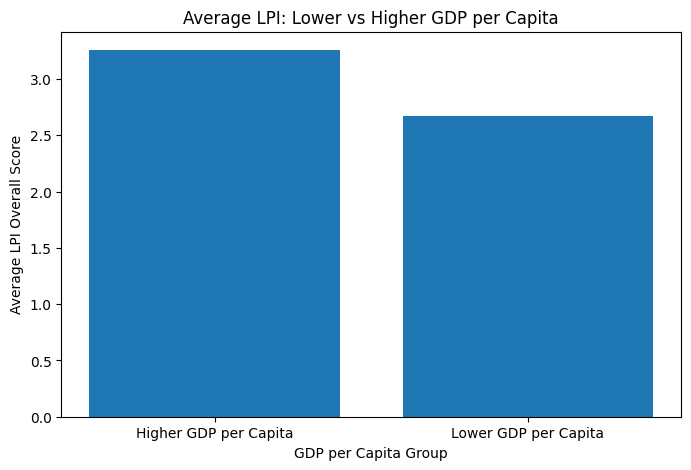

Higher GDP per Capita    3.257297
Lower GDP per Capita     2.675541
Name: LPI Overall Score, dtype: float64


In [ ]:
# Graph 10: Average LPI for lower- and higher-GDP groups
median_gdp = analysis_data["GDP per Capita"].median()
gdp_group = np.where(analysis_data["GDP per Capita"] < median_gdp, "Lower GDP per Capita", "Higher GDP per Capita")
group_means = analysis_data.groupby(gdp_group)["LPI Overall Score"].mean()

plt.figure(figsize=(8, 5))
plt.bar(group_means.index, group_means.values)
plt.xlabel("GDP per Capita Group")
plt.ylabel("Average LPI Overall Score")
plt.title("Average LPI: Lower vs Higher GDP per Capita")
plt.show()

print(group_means)


**Interpretation:** The higher-GDP group has an average LPI of approximately **3.26**, compared with approximately **2.68** for the lower-GDP group. This visual difference is consistent with the independent-samples t-test, which found a statistically significant difference between the two groups.

## 15. Optional: Non-Parametric Robustness Checks

The project instructions allow non-parametric tests. These checks are useful because GDP per capita is highly dispersed and the group-based analyses may not satisfy all parametric assumptions perfectly.

- Mann–Whitney U: two GDP median-split groups
- Kruskal–Wallis: four GDP quartile groups

These are **supplementary robustness checks**, not replacements for the primary classroom tests.


In [ ]:
# 14A. Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    low_gdp,
    high_gdp,
    alternative="two-sided"
)

print("Mann-Whitney U =", u_stat)
print("p-value =", p_value)

if p_value < 0.05:
    print("Interpretation: The two GDP groups differ significantly in their LPI distributions.")
else:
    print("Interpretation: No significant difference in the LPI distributions was detected.")


Mann-Whitney U = 1187.5
p-value = 2.6297870813037095e-09
Interpretation: The two GDP groups differ significantly in their LPI distributions.


In [ ]:
# 14B. Kruskal-Wallis test
h_stat, p_value = kruskal(*groups)

print("Kruskal-Wallis H =", h_stat)
print("p-value =", p_value)

if p_value < 0.05:
    print("Interpretation: At least one GDP quartile differs significantly in its LPI distribution.")
else:
    print("Interpretation: No significant difference among the GDP-quartile LPI distributions was detected.")


Kruskal-Wallis H = 54.44868166381372
p-value = 9.001606283904309e-12
Interpretation: At least one GDP quartile differs significantly in its LPI distribution.


## 16. Correlation Screening for All Main Variables

This is useful for the project because it shows whether LPI is related to exports, trade, GDP per capita and FDI. The main formal regression remains GDP per capita → LPI because GDP per capita has the strongest simple linear relationship with LPI among these four predictors.


In [ ]:
# 15. Pearson correlations with LPI
correlation_results = []

for variable in [
    "Exports(%GDP)",
    "Trade(%GDP)",
    "GDP per Capita",
    "FDI(%GDP)"
]:
    r, p = pearsonr(
        analysis_data[variable],
        analysis_data["LPI Overall Score"]
    )
    correlation_results.append({
        "Variable": variable,
        "Correlation (r)": r,
        "p-value": p
    })

correlation_table = pd.DataFrame(correlation_results)
display(correlation_table)


,Variable,Correlation (r),p-value
0,Exports(%GDP),0.320459,7.165269e-05
1,Trade(%GDP),0.310372,1.234990e-04
2,GDP per Capita,0.617805,6.052476e-17
3,FDI(%GDP),-0.007709,9.259111e-01


## 17. Final Statistical Decision Summary

Use the output from the cells above in the final report. The project instructions specifically require interpretation in business language, managerial implications, limitations, and consistency between report, PPT and video. fileciteturn0file1L85-L114

### Main findings from the current data
- Average LPI ≈ **2.966**
- One-sample t-test vs 3.0: **not significant** (p ≈ 0.486)
- Independent t-test: higher-GDP group has significantly higher mean LPI (p < 0.001)
- Chi-square: GDP category and LPI category are significantly associated (p < 0.001), with the categorisation limitation noted above
- ANOVA: LPI differs significantly across GDP quartiles (p < 0.001)
- Pearson correlation: **r ≈ 0.618**, p < 0.001
- Simple regression: **R² ≈ 0.382**, slope p < 0.001
- Paired t-test: **not applicable**
- Z-test: **not applicable because population SD is not known**

### Important reporting rule
Do not write that GDP per capita *causes* better logistics performance. The analyses establish statistical association/predictive relationship in this cross-sectional dataset, not causation.


## 18. Suggested Business Interpretation

The analysis indicates a statistically significant positive relationship between GDP per capita and logistics performance across the countries in the dataset. Higher-income groups show higher average LPI scores, and the regression model indicates that GDP per capita explains a meaningful share of the observed variation in LPI.

For managers and policymakers, the evidence suggests that logistics performance and broader economic development are closely connected. However, GDP per capita alone does not explain all variation in logistics performance. Other factors such as infrastructure, customs efficiency, trade facilitation, technology, institutions and supply-chain capabilities may also matter.

Because this is cross-sectional secondary data, the findings should be treated as evidence of association rather than causal proof. The project should also report the dataset source, period, unit of analysis, measurement scales, cleaning and limitations, as required in the project instructions.
